# Comparative Evaluation of Reflection-Based Workflows for LinkedIn Content Generation

## 1\. Project Overview

This project investigates the impact of Reflection and Python-based validation on the quality of AI-generated LinkedIn posts.

The main objective is to compare three content-generation workflows and understand how iterative feedback and external validation influence the final output.

Rather than relying on subjective impressions, the experiment uses quantitative evaluation criteria and data visualization to analyze the performance of each workflow.

The project focuses on three main questions:

1-Does Reflection improve the quality of AI-generated content?

2-Does combining Reflection with Python-based validation provide additional improvements?

3-How do these workflows perform across different evaluation criteria and user prompts?

## 2\. Environment Setup and Required Libraries

The experiment uses Python and several libraries for API communication, data processing, parallel execution, and visualization.

**Libraries and their purposes:**

- `pandas`: Organizing and analyzing experimental results using DataFrames.
- `numpy`: Numerical operations and data manipulation.
- `matplotlib`: Creating and customizing charts.
- `seaborn`: Creating statistical visualizations, particularly heatmaps.
- `json`: Storing and retrieving structured experimental results.
- `re`: Extracting hashtags using regular expressions.
- `time`: Measuring the total execution time.
- `ThreadPoolExecutor`: Running independent workflows concurrently.
- `OpenAI`: Communicating with the LLM API through an OpenAI-compatible interface.

The `model` variable defines the language model used for content generation, reflection, and evaluation.


In [91]:
import time
import json
import re
import pandas as pd
from openai import OpenAI
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor


client = OpenAI(base_url='https://api.gapgpt.app/v1', api_key='.....')
model="gpt-4o"

## 3\. Experimental Prompts

Eight different prompts were designed to evaluate the workflows across multiple content-generation scenarios.

The prompts cover topics such as:

- Industrial automation.
- Lessons learned from project failures.
- Educational content about Python.
- Data quality in machine learning.
- Challenges of deploying machine learning models.
- Quantum computing.
- AI agents.
- Professional announcements.

Using different topics helps examine whether workflow performance remains consistent across different content requirements.

Each prompt is processed by all three workflows, allowing the generated outputs to be compared under the same initial request.


In [92]:
prompts = [
    "یک پست لینکدین درباره تأثیر اتوماسیون بر صنایع سنتی تولید کن.",
    "یک پست حرفه‌ای بنویس که در آن درسی را که از شکست یک پروژه فناوری گرفته شده، به اشتراک بگذاری.",
    "یک پست لینکدین برای شروع دوره پایتون پیشرفته که ترغیب کننده  باشد بنویس",
    "یک پست لینکدین تولید کن که توضیح دهد چرا کیفیت داده‌ها در یادگیری ماشین اهمیت دارد.",
    "یک پست درباره چالش‌های استقرار مدل‌های یادگیری ماشین در محیط واقعی و عملیاتی بنویس.",
    "یک پست لینکدین درباره رایانش کوانتومی بنویس و این مفهوم را برای مخاطبان عمومی حوزه فناوری معرفی کن.",
    "یک پست لینکدین درباره مزایا و محدودیت‌های عامل‌های هوش مصنوعی (AI Agents) تولید کن.",
    "یک پست لینکدین درباره اعلام شروع پوزیشن جدید مهندس یادگیری . درشرکت مایکروسافت بگو"]

## 4\. Initial Draft Generation


The `generate_draft()` function is responsible for generating the initial LinkedIn post.

The function receives a user prompt and sends it to the language model along with specific content-generation instructions.

The generated post must follow two structural constraints:

- Maximum length: 500 characters.
- Hashtag count: Between 3 and 8.

The `tone` parameter defines the requested writing style, while the `temperature` parameter controls the randomness of the model's generation.

A temperature of `1.0` allows relatively diverse and creative outputs.

The function returns the generated text, which becomes the shared initial draft for the three workflows.

In [93]:
def generate_draft(prompt:str,model:str=model,tone: "str"="حرفه ای"):
    instruction=f"""
    You are a senior content creator on LinkedIn with extensive and
    successful experience in this field. Based on the topic requested by the 
    user in their prompt, write an engaging LinkedIn caption—maximum 500 characters 
    long—that includes 3 to 8 hashtags.
    
    Tone:
    {tone}
  
    Prompt:{prompt}
    """
    response=client.chat.completions.create(model=model,messages=[{"role":"user","content":instruction}],temperature=1.0)
    return response.choices[0].message.content

## 5\. Reflection and Qualitative Feedback

The `reflect_on_draft()` function introduces a feedback-based evaluation stage.

Instead of immediately accepting the generated post, the language model acts as a content editor and evaluates the draft using six qualitative criteria:

1. Relevance
2. Hook
3. Value
4. Originality
5. Readability
6. Call to Action

Each criterion is scored independently on a scale from 1 to 5.

In addition to numerical scores, the model identifies strengths, weaknesses, and potential unsupported factual claims.

The function returns structured feedback in JSON format.

This feedback is intended to identify specific weaknesses in the original draft and provide actionable suggestions for improvement.

An important design decision is that the reflection stage evaluates the draft but does not directly rewrite it. Revision is handled by a separate function.


In [94]:
def reflect_on_draft(prompt: str,draft: str,model: str = model,tone: "str"="حرفه ای"):
    instruction = f"""
You are a strict LinkedIn content editor and qualitative evaluator.

Your task is to evaluate the generated LinkedIn post based on:
1. The original user prompt.
2. The requested tone.
3. The six qualitative evaluation criteria.

ORIGINAL USER PROMPT:
{prompt}

Tone:
{tone}

GENERATED DRAFT:
{draft}

EVALUATION CRITERIA:

Score each criterion independently from 1 to 5.

1. Relevance:
Does the post address the user's exact topic, intent, and requirements?

2. Hook:
Does the opening capture attention and create curiosity?

3. Value:
Does the post provide a specific insight, practical takeaway,
example, or actionable idea?

4. Originality:
Does it avoid clichés, generic statements, and repetition?
Does it offer a distinctive perspective?

5. Readability:
Is the post clear, concise, coherent, and easy to understand?

6. Call to Action:
Does the ending encourage a relevant response or action?


SCORING GUIDELINES:

1 = Very poor
2 = Weak
3 = Acceptable
4 = Good
5 = Excellent

Use the scoring scale consistently.
Evaluate each criterion independently and support your judgments
with evidence from the draft.


ADDITIONAL QUALITATIVE CHECKS:

- Check whether the language of the draft matches the language
  of the original user prompt.
- Check whether the writing style follows the requested tone.
- Identify unsupported factual claims, fabricated statistics,
  or personal experiences that were not provided by the user.
- Do not automatically label an unsupported claim as false.
  Flag it as requiring verification.
- Check whether the draft follows the user's original intent.
- Identify specific strengths and weaknesses.

The LinkedIn post must satisfy:
- Maximum 500 characters.
- Between 3 and 8 relevant hashtags.

OUTPUT FORMAT:

Return valid JSON only, using exactly this structure:

{{
    "scores": {{
        "relevance": 1,
        "hook": 1,
        "value": 1,
        "originality": 1,
        "readability": 1,
        "call_to_action": 1
    }},
    "strengths": [
        "Specific strength supported by evidence"
    ],
    "issues": [
        {{
            "problem": "Specific issue",
            "evidence": "Exact phrase or explanation",
            "suggestion": "Actionable improvement"
        }}
    ],
    "language_match": true,
    "unsupported_claims": []
}}


IMPORTANT RULES:

- Return valid JSON only.
- All six scores must be integers between 1 and 5.
- Do not calculate weighted scores.
- Do not count characters or hashtags.
- Do not evaluate structural constraints.
- Do not determine whether the post passes or fails.
- Do not generate a revised version of the post.
- Do not invent evidence or facts.
- Use an empty array when no strengths, issues, or unsupported
  claims are identified.
- Be specific, objective, and critical.
- Do not praise the draft without evidence.
- Focus exclusively on qualitative content evaluation.
"""
    response = client.chat.completions.create(model=model,messages=[{"role": "user","content": instruction}],temperature=1.0)
    return response.choices[0].message.content

## 6\. Draft Revision


The `revise_draft()` function receives the original draft and the feedback generated during the reflection stage.

Its responsibility is to produce an improved version of the post based on the identified issues and suggested improvements.

The revision process preserves the original content-generation requirements, including the character limit and hashtag range.

Separating evaluation from revision makes the workflow modular and allows the feedback-generation and revision stages to be examined independently.


In [95]:
def revise_draft(draft:str,feedback:str,model:str=model,tone:str="حرفه ای"):
    instruction = f"""
        Revise the following linkedin caption draft using the feedback provided.
        Make improvements .
        Return only the improved caption.
        Note that the text must be a maximum of 500 characters long and include 3 to 8 relevant hashtags.
        
        Original Draft:
        {draft}
    
        Feedback:
        {feedback}

        Tone:{tone}

        """
    response = client.chat.completions.create(model=model,messages=[{"role": "user","content": instruction}],temperature=1.0)
    return response.choices[0].message.content


## 7\. Python-Based Structural Validation

The `check_post_quality()` function performs external structural validation using Python.

Unlike qualitative evaluation, these checks are deterministic and based on measurable properties of the generated text.

The function calculates:

- Character count.
- Whether the character limit is satisfied.
- Hashtag count.
- Whether the hashtag range is satisfied.

Regular expressions are used to identify hashtags.

The validation rules are:

- Maximum 500 characters.
- Minimum 3 hashtags.
- Maximum 8 hashtags.

The function returns a dictionary containing the calculated measurements and Boolean validation results.

In [96]:
def check_post_quality(post_text, max_length=500, min_hashtags=3, max_hashtags=8):
    quality_signals={
       "length": 0,
       "within_length_limit": False,
       "hashtag_count": 0,
       "within_hashtag_range": False
    }
    quality_signals["length"]=len(post_text)
    hashtags = re.findall(r'(?<!\w)#[\w‌]+', post_text)
    quality_signals["hashtag_count"]=len(hashtags)

    if len(post_text)<=max_length:
        quality_signals["within_length_limit"]=True

    if min_hashtags<=quality_signals["hashtag_count"]<=max_hashtags:
        quality_signals["within_hashtag_range"]=True

    return quality_signals

## 8\. Reflection with External Validation Feedback

The `reflect_on_draft_external_feedback()` function extends the reflection process by providing Python-calculated quality signals to the language model.

The model receives both the original draft and externally verified measurements.

Python is treated as the authoritative source for character and hashtag counts. The model is instructed not to recalculate or modify these values.

This creates a separation of responsibilities:

- Python handles deterministic structural validation.
- The LLM evaluates qualitative content characteristics.

The purpose of this workflow is to examine whether providing explicit external validation signals can help the reflection stage produce more effective revisions.


In [97]:
def reflect_on_draft_external_feedback(prompt: str,draft: str,quality_signals: dict,model: str = model,tone: str="حرفه ای"):
    instruction = f"""
You are a strict LinkedIn content editor and qualitative evaluator.

Your task is to evaluate the generated LinkedIn post based on:
1. The original user prompt.
2. The requested tone.
3. The six qualitative evaluation criteria.
4. The quality signals calculated and verified externally using Python.

ORIGINAL USER PROMPT:
{prompt}

REQUESTED TONE:
{tone}

GENERATED DRAFT:
{draft}

PYTHON-VERIFIED QUALITY SIGNALS:
{quality_signals}

IMPORTANT RULES FOR PYTHON QUALITY SIGNALS:

- Python calculations are authoritative and must be respected.
- Treat the Python-provided character count as the definitive value.
- Treat the Python-provided hashtag count as the definitive value.
- Do NOT recount, estimate, or independently calculate these values.
- Do NOT contradict, modify, or replace Python results.
- Recognize all validation metrics provided by Python.
- Use these metrics directly when evaluating structural compliance.
- If a Boolean validation field is False, identify it as a violation.
- If a Boolean validation field is True, treat that constraint as satisfied.
- Do not confuse structural validation with qualitative evaluation.
- Python determines measurable constraints; you determine content quality.

EVALUATION CRITERIA:

Score each criterion independently from 1 to 5.

1. Relevance:
Does the post address the user's exact topic, intent, and requirements?

2. Hook:
Does the opening capture attention and create curiosity?

3. Value:
Does the post provide a specific insight, practical takeaway,
example, or actionable idea?

4. Originality:
Does it avoid clichés, generic statements, and repetition?
Does it offer a distinctive perspective?

5. Readability:
Is the post clear, concise, coherent, and easy to understand?

6. Call to Action:
Does the ending encourage a relevant response or action?

SCORING GUIDELINES:

1 = Very poor
2 = Weak
3 = Acceptable
4 = Good
5 = Excellent

Use the scoring scale consistently.
Evaluate each criterion independently and support your judgments
with evidence from the draft.

ADDITIONAL QUALITATIVE CHECKS:

- Check whether the language matches the original user prompt.
- Check whether the writing style follows the requested tone.
- Identify unsupported factual claims, fabricated statistics,
  or personal experiences not provided by the user.
- Do not automatically label unsupported claims as false.
  Flag them as requiring verification.
- Check whether the draft follows the user's original intent.
- Identify specific strengths and weaknesses.
- Evaluate whether hashtags are relevant to the actual topic.
- Do not reward generic content simply because it meets
  the character and hashtag requirements.

STRUCTURAL VALIDATION:

The LinkedIn post must satisfy:
- Maximum 500 characters.
- Between 3 and 8 relevant hashtags.

Use ONLY the Python-provided quality signals to determine
whether these requirements are satisfied.

OUTPUT FORMAT:

Return valid JSON only, using exactly this structure:

{{
    "scores": {{
        "relevance": 1,
        "hook": 1,
        "value": 1,
        "originality": 1,
        "readability": 1,
        "call_to_action": 1
    }},
    "strengths": [
        "Specific strength supported by evidence"
    ],
    "issues": [
        {{
            "problem": "Specific issue",
            "evidence": "Exact phrase or Python quality signal",
            "suggestion": "Actionable improvement"
        }}
    ],
    "validation": {{
        "character_count": 0,
        "within_length_limit": true,
        "hashtag_count": 0,
        "within_hashtag_range": true,
        "language_match": true,
        "unsupported_claims": []
    }},
    "verdict": "pass or revise"
}}

IMPORTANT OUTPUT RULES:

- Return valid JSON only.
- All six scores must be integers between 1 and 5.
- Do not calculate weighted scores.
- Do not introduce weights or percentages.
- Copy character_count, within_length_limit,
  hashtag_count, and within_hashtag_range directly
  from PYTHON-VERIFIED QUALITY SIGNALS.
- Preserve Python-provided values exactly.
- Do not invent missing validation values.
- Use an empty array when no strengths, issues,
  or unsupported claims are identified.
- Do not generate a revised version of the post.
- Do not invent evidence or facts.

VERDICT RULES:

Set verdict to "pass" only if:
- All six qualitative scores are at least 3.
- The character limit is satisfied according to Python.
- The hashtag range is satisfied according to Python.
- There are no serious factual issues.
- The post follows the original prompt and requested tone.

Otherwise, set verdict to "revise".

Be specific, objective, and critical.
Do not praise the draft without evidence.
Focus exclusively on evaluation and actionable feedback.
"""
    response = client.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": instruction}],temperature=1.0)
    return response.choices[0].message.content

## 9\. Main Workflow Architectures

Three different workflows are implemented to compare different content-generation strategies.

**Workflow A — Initial Draft**

This workflow generates a LinkedIn post directly from the original prompt without any reflection or revision stage.

**Workflow B — Reflection**

This workflow generates an initial draft, evaluates it using qualitative feedback, and produces a revised version.

**Workflow C — Reflection + Python Validation**

This workflow generates an initial draft, calculates structural quality signals using Python, provides these signals to the reflection stage, and produces a revised version.

The three workflows share the same initial draft for each prompt. Workflows B and C are executed independently and concurrently.

This paired design helps reduce differences caused by using unrelated initial drafts when comparing the reflection-based approaches.


In [9]:
def initial_draft_flow(prompt):
    return generate_draft(prompt)


def reflection_flow(prompt, draft):
    feedback = reflect_on_draft(prompt, draft)
    return revise_draft(draft, feedback)


def reflection_validation_flow(prompt, draft, quality_signals):
    feedback = reflect_on_draft_external_feedback(prompt, draft, quality_signals)
    return revise_draft(draft, feedback)


## 10\. Parallel Execution and Result Storage


The `ThreadPoolExecutor` is used to execute the two independent reflection-based workflows concurrently.

The parameter `max_workers=2` allows Workflow B and Workflow C to run at the same time.

The `.submit()` method schedules each workflow, while `.result()` retrieves the corresponding output.

After execution, the generated drafts and their Python-calculated quality signals are stored in a structured results list.

The results are also saved incrementally in JSON format after each processed prompt.

Incremental storage reduces the risk of losing previously collected experimental results if execution is interrupted.

The `time.perf_counter()` function measures the total execution duration.


In [ ]:
Results = []

start_time = time.perf_counter()

for prompt in prompts:

    candidates = [
        {"id": "A", "draft": "", "quality_signals": ""},
        {"id": "B", "draft": "", "quality_signals": ""},
        {"id": "C", "draft": "", "quality_signals": ""}]

    draft1 = initial_draft_flow(prompt)
    quality_signals1 = check_post_quality(draft1)
    
    with ThreadPoolExecutor(max_workers=2) as executor:
        future1 = executor.submit(reflection_flow,prompt,draft1)
        future2 = executor.submit(reflection_validation_flow,prompt,draft1,quality_signals1)

        draft2 = future1.result()
        draft3 = future2.result()
        
    quality_signals2 = check_post_quality(draft2)
    quality_signals3 = check_post_quality(draft3)
    candidates[0]["draft"] = draft1
    candidates[0]["quality_signals"] = quality_signals1

    candidates[1]["draft"] = draft2
    candidates[1]["quality_signals"] = quality_signals2

    candidates[2]["draft"] = draft3
    candidates[2]["quality_signals"] = quality_signals3

    Results.append({
    "prompt_id": len(Results) + 1,
    "prompt": prompt,
    "candidates": candidates})
    with open("experiment_results.json", "w", encoding="utf-8") as f:
        json.dump(Results, f, ensure_ascii=False, indent=4)

end_time = time.perf_counter()

print(f"Total execution time: {end_time - start_time:.2f} seconds")
print(f"Processed prompts: {len(Results)}")

Total execution time: 79.11 seconds
Processed prompts: 8


# ⚖️ 11. LLM-as-a-Judge Evaluation

An independent LLM-based evaluator is introduced to assess the quality of generated candidates.

The `LLM_Judgment()` function evaluates each candidate separately using a predefined weighted scoring rubric.

### 📊 Final Evaluation Rubric

| Criterion | Maximum Score |
|---|---:|
| Relevance | 25 |
| Value | 20 |
| Originality | 15 |
| Hook | 15 |
| Readability | 10 |
| Tone and Language | 10 |
| Call to Action | 5 |
| **Total** | **100** |

### 🔍 Important Configuration

- `temperature=0.2`: Encourages relatively consistent evaluation behavior.
- `criterion_scores`: Stores individual criterion scores.
- `final_score`: Represents the total evaluation score.
- `eligible`: Indicates whether a candidate satisfies the evaluator's eligibility conditions.
- `strength`: Describes the positive aspects of the candidate.
- `weakness`: Identifies areas requiring improvement.
- `reasoning`: Contains the evaluator's explanation.

Each candidate is evaluated independently.

The evaluator is instructed not to compare candidates or assume anything about their generation history.

⚠️ Evaluation Limitation: The evaluator was not provided with workflow identities, reducing potential method-label bias. However, LLM-as-a-Judge may still exhibit inherent biases related to writing style, response length, evaluation criteria, and model preferences. Therefore, the assigned scores should not be considered equivalent to human ground-truth judgments.


In [ ]:
def LLM_Judgment(prompt: str,draft: str,quality_signals: dict,model: str = model,tone: str = "حرفه ای"):
    
    instruction = f"""
You are an independent LinkedIn content evaluator.

Your task is to objectively evaluate ONE LinkedIn post
based on the user's original request, requested tone,
and Python-verified quality signals.

ORIGINAL USER REQUEST:
{prompt}

REQUESTED TONE:

{tone}

GENERATED LINKEDIN POST:
{draft}

PYTHON-VERIFIED QUALITY SIGNALS:
{quality_signals}

==================================================
EVALUATION PRINCIPLES
==================================================

1. The original user's request is the primary source
   of truth.

2. Evaluate only the provided post.
   Do not compare it with other posts.

3. Do not assume anything about the post's
   generation or revision history.

4. Evaluate actual content quality, relevance,
   usefulness, and compliance with the user's intent.

5. Do not reward generic content simply because
   it sounds professional.

6. Python-provided measurements are authoritative.
   Never recalculate, estimate, or contradict them.

7. Evaluate the post independently using the same
   scoring standards for every evaluation.

==================================================
SCORING CRITERIA
==================================================

Score each criterion according to its maximum points.

1. Relevance to User Request (25 points):
Does the post accurately address the user's exact
topic, intention, and specific requirements?

2. Value and Usefulness (20 points):
Does the post provide meaningful insights,
useful information, or practical takeaways?

3. Originality (15 points):
Is the content distinctive, creative, and free
from clichés and generic statements?

4. Hook (15 points):
Does the opening capture attention and encourage
the reader to continue?

5. Readability (10 points):
Is the content clear, coherent, concise,
and easy to understand?

6. Tone and Language Match (10 points):
Does the writing match the requested tone
and the language of the original prompt?

7. Call to Action (5 points):
Does the ending encourage relevant interaction
when appropriate?

SCORING RULES:

- Assign integer scores to every criterion.
- Respect the maximum points of each criterion.
- Calculate final_score as the sum of all seven
  criterion scores.
- Maximum total score is 100.
- Support judgments with evidence from the post.
- Do not inflate scores.
- Do not award points without justification.

==================================================
PYTHON VALIDATION
==================================================

Mandatory requirements:
- Maximum 500 characters.
- Between 3 and 8 relevant hashtags.

Use Python quality signals as the ONLY authority
for character and hashtag measurements.

- Copy all provided validation values exactly.
- Never recalculate or modify Python measurements.
- If a required validation field is missing,
  use null and mark the post ineligible.
- A post violating either mandatory requirement
  cannot be eligible.

A post is eligible only if:
1. Character limit is satisfied.
2. Hashtag range is satisfied.
3. It substantially fulfills the user's request.
4. No serious factual issues are identified.

==================================================
OUTPUT FORMAT
==================================================

Return valid JSON only:

{{
    "criterion_scores": {{
        "relevance": 0,
        "value": 0,
        "originality": 0,
        "hook": 0,
        "readability": 0,
        "tone_and_language": 0,
        "call_to_action": 0
    }},
    "final_score": 0,
    "eligible": true,
    "validation": {{
        "character_count": null,
        "within_length_limit": null,
        "hashtag_count": null,
        "within_hashtag_range": null
    }},
    "strength": "Main strength supported by evidence",
    "weakness": "Main weakness supported by evidence",
    "reasoning": "Brief explanation of the overall score"
}}

FINAL RULES:

- Return valid JSON only.
- All criterion scores must be integers.
- All final scores must be between 0 and 100.
- Never exceed criterion maximum points.
- Copy Python validation values exactly.
- Do not invent missing measurements.
- Do not rewrite or improve the post.
- Do not compare it with other candidates.
- Do not use previous LLM scores as a substitute
  for your own evaluation.
- Be objective, consistent, and critical.
"""

    response = client.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": instruction}],temperature=0.2)

    return response.choices[0].message.content

## 12\. Data Preparation and DataFrame Construction

After evaluation, the nested experimental results are transformed into a tabular structure using Pandas.

Each row represents one generated candidate for a specific prompt.

The resulting DataFrame contains:

- Prompt ID
- Candidate ID
- Generated draft
- Final score
- Seven criterion scores
- Character count
- Hashtag count

The `next()` function is used to match each candidate with its corresponding evaluation using the candidate ID.

This ensures that evaluation scores are associated with the correct generated draft rather than relying only on list ordering.

The resulting dataset contains 24 observations: 8 prompts multiplied by 3 workflows.

This structured format makes the experimental results easier to filter, aggregate, compare, and visualize.


In [ ]:
total_scores = []

for i, item in enumerate(Results):

    evaluated_candidates = []

    for candidate in item["candidates"]:

        result = LLM_Judgment(
            prompt=item["prompt"],
            draft=candidate["draft"],
            quality_signals=candidate["quality_signals"])

        if result.startswith("```json"):
            result = result.removeprefix("```json").removesuffix("```").strip()
        elif result.startswith("```"):
            result = result.removeprefix("```").removesuffix("```").strip()

        evaluation = json.loads(result)

        evaluated_candidates.append({
            "id": candidate["id"],
            "draft": candidate["draft"],
            "evaluation": evaluation,
            "final_score": evaluation["final_score"],
            "eligible": evaluation["eligible"]
        })

    total_scores.append(evaluated_candidates)

In [ ]:
rows = []

for i, result in enumerate(Results):

    for candidate in result["candidates"]:

        score = next(s for s in total_scores[i] if s["id"] == candidate["id"])
        evaluation = score["evaluation"]
        criteria = evaluation["criterion_scores"]
        quality = candidate["quality_signals"]

        row = {
            "prompt_id": result["prompt_id"],
            "candidate_id": candidate["id"],
            "draft": candidate["draft"],
            "final_score": evaluation["final_score"],
            "relevance": criteria["relevance"],
            "value": criteria["value"],
            "originality": criteria["originality"],
            "hook": criteria["hook"],
            "readability": criteria["readability"],
            "tone_and_language": criteria["tone_and_language"],
            "call_to_action": criteria["call_to_action"],
            "character_count": quality["length"],
            "hashtag_count": quality["hashtag_count"],
        }
        rows.append(row)
final_df = pd.DataFrame(rows)
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   prompt_id          24 non-null     int64 
 1   candidate_id       24 non-null     object
 2   draft              24 non-null     object
 3   final_score        24 non-null     int64 
 4   relevance          24 non-null     int64 
 5   value              24 non-null     int64 
 6   originality        24 non-null     int64 
 7   hook               24 non-null     int64 
 8   readability        24 non-null     int64 
 9   tone_and_language  24 non-null     int64 
 10  call_to_action     24 non-null     int64 
 11  character_count    24 non-null     int64 
 12  hashtag_count      24 non-null     int64 
dtypes: int64(11), object(2)
memory usage: 2.6+ KB


## 13.1 Average Final Score by Workflow

This bar chart compares the average final evaluation score of the three workflows.

The `groupby()` operation groups candidates by workflow, and `mean()` calculates the average final score for each group.

In [ ]:
workflow_names = {
    "A": "Initial Draft",
    "B": "Reflection",
    "C": "Reflection + Python Validation"}

mean_scores = (final_df.groupby("candidate_id")["final_score"].mean().rename(index=workflow_names))

print(mean_scores)

candidate_id
Initial Draft                     85.625
Reflection                        87.750
Reflection + Python Validation    87.875
Name: final_score, dtype: float64


The chart uses:

- `ax.bar()` to create the bars.
- `figsize` to control the figure dimensions.
- `width` to adjust bar width.
- `ax.text()` to display the numerical score above each bar.
- `grid()` to improve visual readability.
- `tight_layout()` to prevent layout overlap.

The average scores are:

| Workflow | Average Score |
| --- | ---: |
| A — Initial Draft | 85.62 |
| B — Reflection | 87.75 |
| C — Reflection + Python Validation | 87.88 |

**Interpretation:**

Both reflection-based workflows achieved higher average scores than the initial-draft workflow.

Workflow B improved the average score by approximately 2.13 points compared with Workflow A.

Workflow C achieved an average score approximately 2.25 points higher than Workflow A.
The difference between Workflows B and C was only 0.13 points.

These results suggest that Reflection contributed to improved evaluation scores in this experiment. However, the additional contribution of Python-based validation to the final qualitative score appears limited in this dataset.

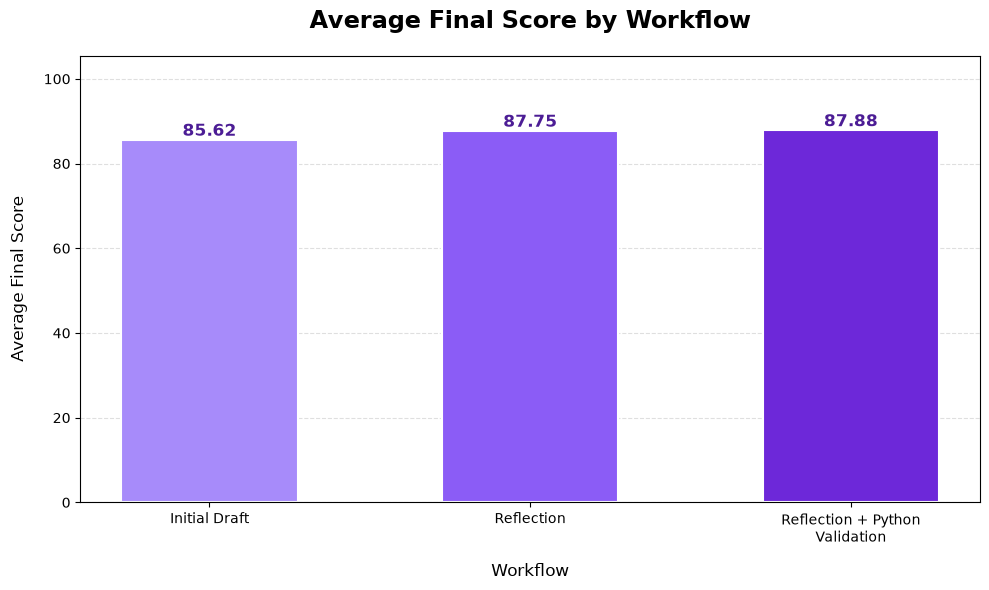

In [ ]:
workflow_names = ["Initial Draft","Reflection","Reflection + Python\nValidation"]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    workflow_names,
    mean_scores,
    width=0.55,
    color=["#A78BFA", "#8B5CF6", "#6D28D9"],
    edgecolor="white",
    linewidth=1.5)


for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color="#4C1D95"
    )
ax.set_title("Average Final Score by Workflow",fontsize=17,fontweight="bold",pad=20)
ax.set_xlabel("Workflow", fontsize=12, labelpad=12)
ax.set_ylabel("Average Final Score", fontsize=12, labelpad=12)
ax.set_ylim(0, max(mean_scores) * 1.2)
ax.grid(axis="y",linestyle="--",alpha=0.4)
ax.set_axisbelow(True)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

## 13.2 🔎 Workflow Performance Across Prompts

This grouped bar chart compares the final scores of all three workflows for each individual prompt.

The `pivot()` method transforms the dataset into a wide-format structure.

### 🔍 Important Parameters

- `index="prompt_id"`: Uses prompt IDs as row identifiers.
- `columns="candidate_id"`: Creates separate columns for workflows.
- `values="final_score"`: Specifies the values to display.

The Y-axis is maintained within the `0–100` evaluation range.

### 💡 Interpretation

The visualization demonstrates how workflow performance changes across different prompts.

Reflection-based workflows frequently achieved higher scores than the initial-draft approach.

However, the amount of improvement varied between prompts.

Some prompts produced similar results across all workflows, while others showed more noticeable differences.

This suggests that the effectiveness of Reflection may depend partly on the topic and complexity of the original prompt.

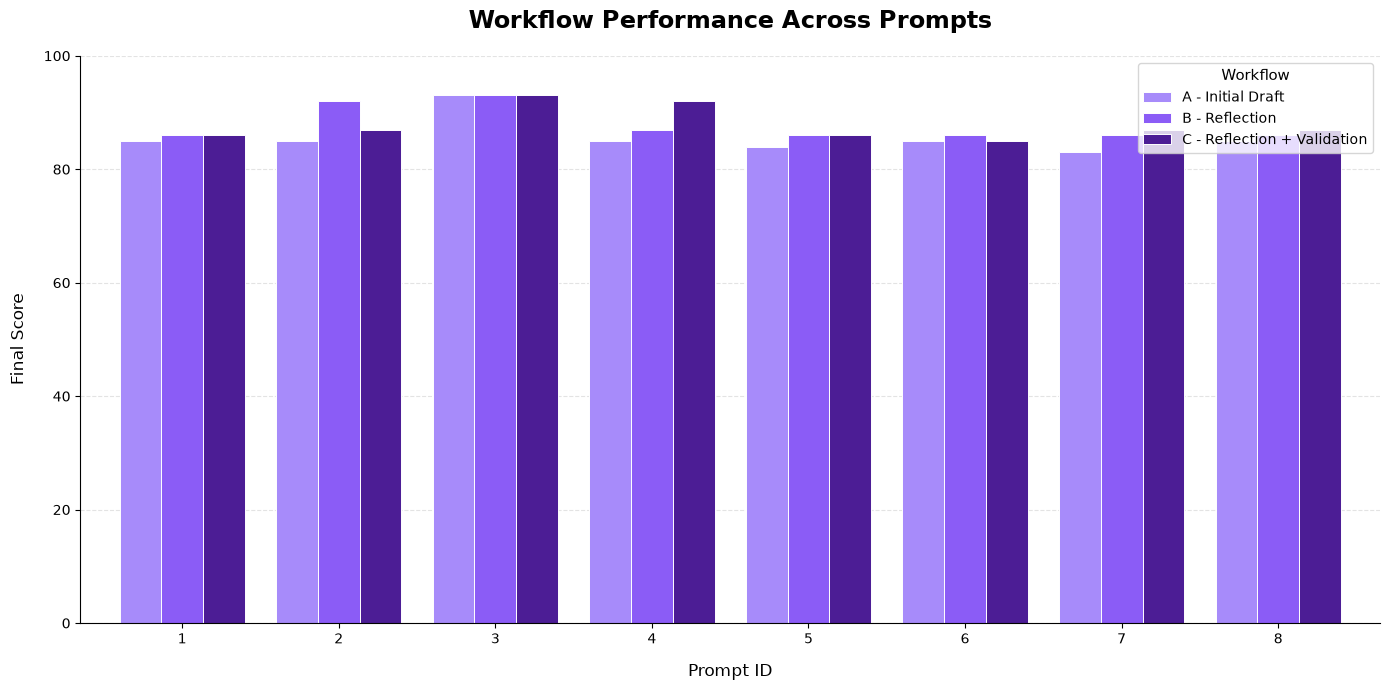

In [ ]:
pivot_df = final_df.pivot(index="prompt_id",columns="candidate_id",values="final_score")

ax = pivot_df.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8,
    color=["#A78BFA", "#8B5CF6", "#4C1D95"],
    edgecolor="white",
    linewidth=0.7
)

ax.set_title("Workflow Performance Across Prompts",fontsize=17,fontweight="bold",pad=20)
ax.set_xlabel("Prompt ID", fontsize=12, labelpad=12)
ax.set_ylabel("Final Score", fontsize=12, labelpad=12)
ax.set_ylim(0, 100)
ax.grid(axis="y",linestyle="--",alpha=0.35)
ax.set_axisbelow(True)
ax.legend(
    title="Workflow",
    labels=["A - Initial Draft", 
            "B - Reflection", 
            "C - Reflection + Validation"],
    fontsize=10,
    title_fontsize=11
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

## 13.3 🌡️ Evaluation Criteria Heatmap

The heatmap provides a criterion-level comparison of the three workflows.

The average score of each evaluation criterion is calculated for every workflow using `groupby()` and `mean()`.

The `T` attribute transposes the resulting DataFrame so that evaluation criteria appear as rows and workflows appear as columns.

### 🔍 Important `sns.heatmap()` Parameters

| Parameter | Purpose |
|---|---|
| `annot=True` | Displays values inside each cell |
| `fmt=".2f"` | Formats values to two decimal places |
| `cmap="Purples"` | Defines the color palette |
| `linewidths=1` | Adds separation between cells |
| `linecolor="white"` | Defines cell boundary color |
| `cbar_kws` | Customizes the color bar |

### 💡 Interpretation

The heatmap reveals how different evaluation criteria respond to each workflow.

The results indicate that reflection-based workflows achieved higher scores across several qualitative dimensions.

However, improvements were not uniform across all criteria.

Some criteria showed little or no variation, suggesting that Reflection did not influence every aspect of content quality equally.

This visualization provides a more detailed understanding of workflow performance than the overall average score alone.


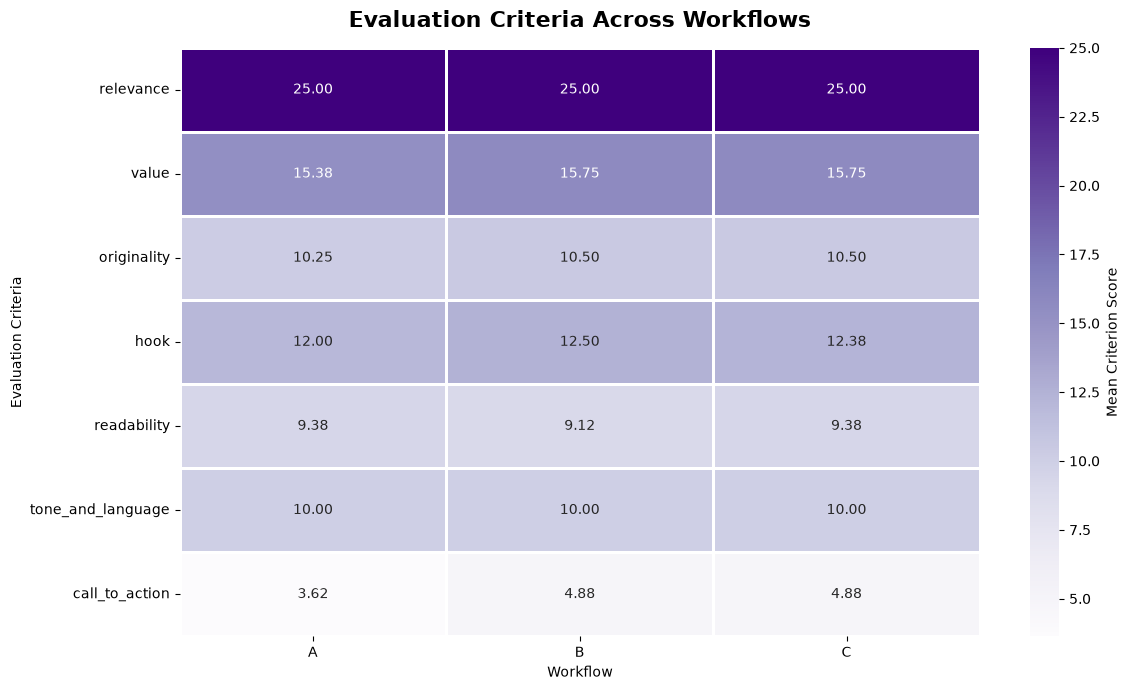

In [ ]:
criteria = [
    "relevance",
    "value",
    "originality",
    "hook",
    "readability",
    "tone_and_language",
    "call_to_action"]

criteria_mean = final_df.groupby("candidate_id")[criteria].mean()
heatmap_df = criteria_mean.T
plt.figure(figsize=(12, 7))

sns.heatmap(
    data=heatmap_df,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Mean Criterion Score"}
)

plt.title("Evaluation Criteria Across Workflows", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Workflow")
plt.ylabel("Evaluation Criteria")
plt.tight_layout()
plt.show()

## 13.4 📍 Character Count vs. Final Score

This scatter plot investigates the relationship between generated post length and final evaluation score.

Each point represents one generated candidate.

### 🔍 Important `sns.scatterplot()` Parameters

- `x="character_count"`: Character count of each post.
- `y="final_score"`: Final evaluation score.
- `hue="candidate_id"`: Assigns different colors to workflows.
- `style="candidate_id"`: Uses different marker styles.
- `s=100`: Controls marker size.

### 💡 Interpretation

The visualization helps investigate whether longer posts tend to receive higher evaluation scores.

The collected results suggest that reflection-based workflows frequently produced longer posts and often achieved higher scores.

This may indicate that the revision process provides opportunities to develop ideas, clarify explanations, and add useful details.

However, longer content is not necessarily better content.

The observed relationship is descriptive and does not establish a causal relationship between character count and content quality.

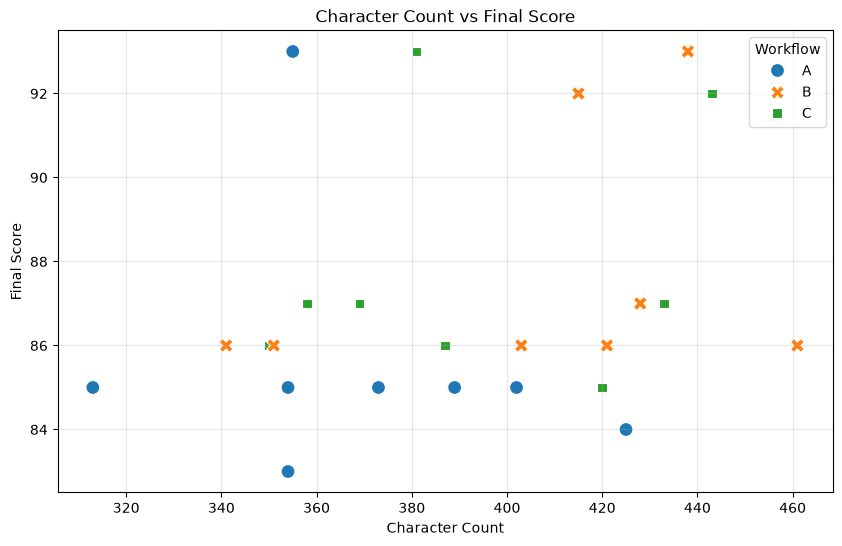

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=final_df,
    x="character_count",
    y="final_score",
    hue="candidate_id",
    style="candidate_id",
    s=100
)
plt.title("Character Count vs Final Score",fontsize=17,fontweight="bold",pad=20)
plt.xlabel("Character Count")
plt.ylabel("Final Score")
plt.legend(title="Workflow")
plt.grid(alpha=0.3)
plt.show()

## 13.5 📈 Workflow Performance Across Prompts — Line Plot


The line plot provides another perspective on workflow performance across individual prompts.

The previously generated `pivot_df` is reused to visualize score changes for each workflow.

### 🔍 Important Parameters

- `kind="line"`: Creates a line chart.
- `marker="o"`: Displays circular markers.
- `figsize`: Controls figure dimensions.
- `ylim(0, 100)`: Maintains the evaluation score range.

### 💡 Interpretation

The line plot makes it easier to observe score variations and compare the relative performance of workflows across prompts.

A higher line indicates a higher evaluation score for the corresponding prompt.

The visualization supports the observation that reflection-based workflows frequently outperform the initial-draft approach.

It also highlights prompts where all workflows achieve similar results, showing that Reflection does not necessarily produce the same improvement in every scenario.


<Figure size 1100x600 with 0 Axes>

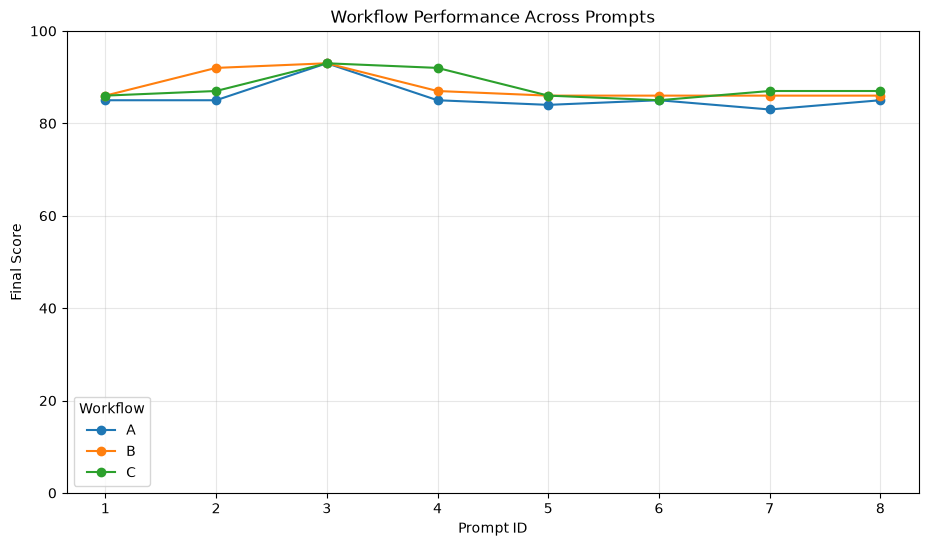

In [ ]:
plt.figure(figsize=(11, 6))
pivot_df.plot(kind="line",marker="o",figsize=(11, 6))
plt.title("Workflow Performance Across Prompts",fontsize=17,fontweight="bold",pad=20)
plt.xlabel("Prompt ID")
plt.ylabel("Final Score")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend(title="Workflow")
plt.show()

# 🧪 14. Experimental Findings | یافته‌های آزمایش

Based on the collected results from eight prompts and three workflows, several important observations can be made.

### ① Reflection and Evaluation Scores

The Reflection workflow achieved an average score of `87.75`, compared with `85.62` for the Initial Draft workflow.

This represents an average increase of approximately `2.13` points.

### ② Reflection + Python Validation

Workflow C achieved the highest average score of `87.88`.

However, its improvement over standard Reflection was only approximately `0.13` points.

### ③ Criterion-Level Improvements

The criterion-level analysis showed that reflection-based workflows achieved higher scores across several qualitative dimensions.

However, improvements varied between evaluation criteria.

### ④ Changes in Generated Content Length

Reflection-based workflows frequently produced longer outputs and often achieved higher evaluation scores.

This suggests that iterative revision may help the model develop ideas and provide more detailed explanations.

### 📌 Overall Finding

The collected results suggest that introducing a Reflection stage can improve the evaluated quality of AI-generated LinkedIn posts within the scope of this experiment.

The additional contribution of Python-based structural validation to qualitative scores was considerably smaller.

These findings are preliminary and should be interpreted within the limitations of the current dataset.

# ⚠️ 15. Limitations & Methodological Considerations


Although this experiment provides useful insights, several limitations should be considered when interpreting the results.

### ① Limited Dataset Size

The experiment includes only eight prompts.

A larger and more diverse dataset is required to determine whether the observed improvements generalize to other content-generation scenarios.

### ② LLM-as-a-Judge Limitations

The final scores are generated by an LLM evaluator rather than human reviewers.

Although a predefined rubric is used, the evaluator may still introduce systematic scoring biases.

### ③ Structural Validation vs. Qualitative Evaluation

Character count and hashtag count are calculated using Python.

These measurements verify structural constraints but do not independently measure readability, originality, usefulness, or engagement potential.

### ④ Limited Evidence for the Additional Effect of Python Validation

The average difference between Workflows B and C is very small.

Therefore, the current results do not establish a substantial qualitative improvement caused by adding Python-based validation.

### ⑤ Different Evaluation Rubrics

The Reflection stage uses six qualitative criteria, whereas the final LLM Judge uses seven weighted criteria.

These stages serve different purposes, and their scores should not be directly compared.

### ⑥ No Statistical Significance Claim

The sample size is insufficient to support strong statistical generalizations or claims of statistical significance.

# 🏁 16. Conclusion 


This experiment investigated how Reflection and Python-based structural validation influence AI-generated LinkedIn content.

Three different workflows were implemented and evaluated using a consistent final scoring framework.

The results showed that both reflection-based approaches achieved higher average evaluation scores than direct draft generation.

Among the three approaches, Reflection + Python Validation achieved the highest average score, although its improvement over standard Reflection was minimal.

The most notable finding was the tendency of reflection-based workflows to produce higher-scoring outputs across multiple prompts and evaluation dimensions.

The experiment highlights the practical value of iterative feedback in AI content-generation systems and demonstrates the importance of separating qualitative evaluation from deterministic programmatic validation.

Future work can investigate larger datasets, human evaluation, and more advanced feedback strategies.

> **The central takeaway:** Generating content is only one part of an AI workflow. Evaluating, reflecting, and improving that content can be equally important.


# 📚 17. Reproducibility & Project Notes

The experimental outputs are stored in structured JSON format, allowing further analysis without repeating the generation process.

The Notebook uses the saved results to construct a Pandas DataFrame and generate the visualizations.

### 🔐 Reproducibility Checklist

- Store API credentials in environment variables.
- Keep experimental results separate from analysis code.
- Document the model name and configuration parameters.
- Preserve the original JSON results.
- Record the evaluation rubric and workflow definitions.
- Ensure that no private credentials or sensitive information are included in the public repository.

This structure makes the analysis more transparent, traceable, and easier to reproduce.